# Questions 5.1 to 5.8

### Imports

In [1]:
import config as cfg
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneGroupOut
import src.loading as ld
import src.normalise as norm
import src.features as ftrs
import src.selection as sel
import src.evaluation as evl

pd.set_option("display.show_dimensions", True)

### Loading Development Data
Only the 20 development actors are loaded (`include_tests=False`). The test actors are loaded in 5.7 only.

In [2]:
dev_df = ld.load_frames(include_tests=False)

### Normalising Data

In [3]:
dev_df_n = norm.normalise_d(dev_df)

### Feature Table

In [4]:
dev_table = ftrs.build_feature_table(dev_df_n)

n_missing = dev_table.isna().sum().sum()
print(f"Number of missing values in development table: {n_missing}" if n_missing > 0 else "There are no missing values")
dev_table

There are no missing values


,,,M1_mean,M1_std,M1_range,M1_vel,M1_energy,M2_mean,M2_std,M2_range,M2_vel,M2_energy,...,own_M10_mean,own_M10_std,own_M10_range,own_M10_vel,own_M10_energy,own_M11_mean,own_M11_std,own_M11_range,own_M11_vel,own_M11_energy
video_id,actor,emotion,,,,,,,,,,,,,,,,,,,,,
01-01-01-01-01-01-02,2,1,0.045541,0.042781,0.166364,0.007619,0.000202,0.572101,0.015992,0.092406,0.004377,0.000064,...,0.183367,0.004399,0.027165,0.001563,0.000006,0.079111,0.001628,0.010187,0.000824,1.278639e-06
01-01-01-01-01-01-03,3,1,0.044769,0.030293,0.120792,0.006470,0.000131,0.618272,0.021215,0.088479,0.006103,0.000098,...,0.243482,0.007515,0.029483,0.002015,0.000009,0.093582,0.001967,0.008644,0.000716,8.003498e-07
01-01-01-01-01-01-04,4,1,0.046652,0.044842,0.216453,0.007799,0.000282,0.629438,0.028067,0.166719,0.006667,0.000127,...,0.200026,0.010811,0.046274,0.003261,0.000022,0.089517,0.003749,0.014985,0.001106,2.325620e-06
01-01-01-01-01-01-05,5,1,0.038562,0.022888,0.086473,0.004317,0.000055,0.616243,0.012968,0.050438,0.002434,0.000013,...,0.220493,0.003229,0.017448,0.000930,0.000002,0.091463,0.002399,0.009352,0.000658,6.669027e-07
01-01-01-01-01-01-06,6,1,0.093865,0.059531,0.254196,0.010456,0.000488,0.614809,0.030068,0.164469,0.007354,0.000262,...,0.174683,0.010864,0.060512,0.002839,0.000020,0.070067,0.003757,0.021606,0.001548,4.984440e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
01-01-08-02-02-02-19,19,8,0.099246,0.028922,0.166773,0.008806,0.000211,0.587483,0.040577,0.164257,0.007240,0.000198,...,0.179338,0.014895,0.055809,0.002880,0.000028,0.068682,0.008618,0.028211,0.001223,3.416902e-06
01-01-08-02-02-02-20,20,8,0.051768,0.031860,0.104523,0.004976,0.000103,0.633839,0.039380,0.108045,0.004447,0.000043,...,0.182769,0.015928,0.055561,0.002451,0.000019,0.080864,0.004708,0.022094,0.001201,3.404490e-06
01-01-08-02-02-02-21,21,8,0.148165,0.057097,0.269216,0.015000,0.000697,0.575554,0.054309,0.227479,0.011514,0.000292,...,0.189731,0.017307,0.077723,0.003340,0.000030,0.083529,0.005857,0.021492,0.001145,2.400981e-06


The development feature table has one row per video (1200) and the 55 features of Section 3: the 30 of Tables 2 and 3 and the 25 of 3.2. The index holds the video, the actor and the emotion.

## 5.1

### Standardising the features
The features have different units and scales (for example, a mean in units of d and an energy in units of d² per frame²), so they are standardised before the PCA: every feature gets mean 0 and standard deviation 1. For exploration only, the scaler and the PCA are fitted on all 1200 development videos; no score is computed in 5.1.

In [5]:
scaler = StandardScaler()
Z = scaler.fit_transform(dev_table)

print(Z.shape)

(1200, 55)


### PCA

In [6]:
pca = PCA()
pca.fit(Z)
scores = pca.transform(Z) # coordinates of each video on the components

cumulative = np.cumsum(pca.explained_variance_ratio_)
n_75 = np.argmax(cumulative >= 0.75) + 1 # first component that reaches 75 %
n_95 = np.argmax(cumulative >= 0.95) + 1

print(f"Components for 75 % of the variance: {n_75}")
print(f"Components for 95 % of the variance: {n_95}")

Components for 75 % of the variance: 8
Components for 95 % of the variance: 23


In [7]:
variance_table = pd.DataFrame({"explained": pca.explained_variance_ratio_,
                               "cumulative": cumulative},
                              index=[f"PC{i + 1}" for i in range(len(cumulative))])
variance_table.head(10).round(3)

,explained,cumulative
PC1,0.365,0.365
PC2,0.133,0.498
PC3,0.070,0.567
PC4,0.057,0.625
PC5,0.043,0.668
PC6,0.038,0.706
PC7,0.035,0.740
PC8,0.027,0.767
PC9,0.024,0.791
PC10,0.023,0.814


**Table: explained variance of the first 10 components.** Share of the total variance explained by each component and cumulative share, out of 55 components.

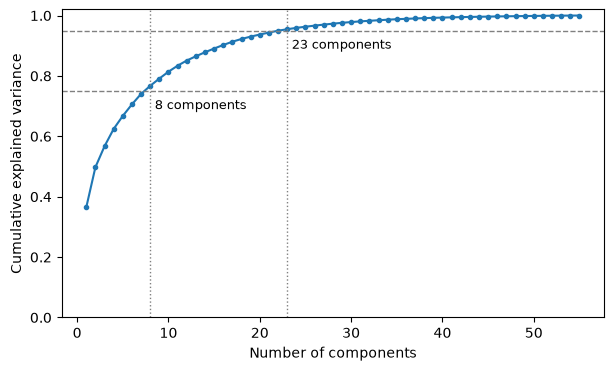

In [8]:
n_components = np.arange(1, len(cumulative) + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_components, cumulative, marker="o", markersize=3)

for level, n in [(0.75, n_75), (0.95, n_95)]:
    ax.axhline(level, color="grey", linestyle="--", linewidth=1)
    ax.axvline(n, color="grey", linestyle=":", linewidth=1)
    ax.text(n + 0.5, level - 0.06, f"{n} components", fontsize=9)

ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.set_ylim(0, 1.02)
plt.show()

**Figure: cumulative explained variance.** Cumulative share of the variance against the number of components kept. Dashed lines: 75 % and 95 % of the variance; dotted lines: the number of components that first reaches each of them.

In [9]:
measure_shares = sel.loadings_by_measure(pca, dev_table.columns, n_components=2)
measure_shares.round(3)

,PC1,PC2
M1,0.127,0.106
M2,0.130,0.041
M3,0.120,0.016
M4,0.043,0.255
M5,0.022,0.208
M6,0.053,0.070
own_M7,0.128,0.019
own_M8,0.124,0.104
own_M9,0.057,0.095
own_M10,0.123,0.016


**Table: share of PC1 and PC2 by measure.** For each component, the squared loadings of the five statistics of a measure are summed. The squared loadings of one component add up to 1, so each column adds up to 1 and each value is the share of that component that comes from the measure.

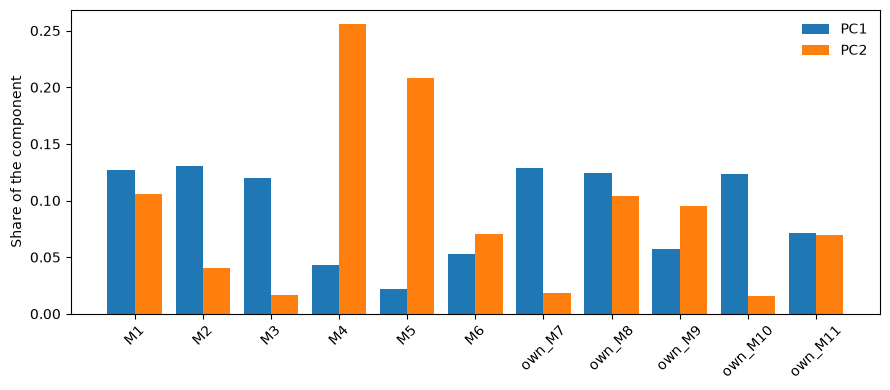

In [10]:
positions = np.arange(len(measure_shares))
width = 0.4

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(positions - width / 2, measure_shares["PC1"], width, label="PC1")
ax.bar(positions + width / 2, measure_shares["PC2"], width, label="PC2")
ax.set_xticks(positions)
ax.set_xticklabels(measure_shares.index, rotation=45)
ax.set_ylabel("Share of the component")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Figure: share of PC1 and PC2 by measure.** The values of the table above, one bar per measure and component.

In [11]:
loadings = sel.loadings_table(pca, dev_table.columns, n_components=2)

top_pc1 = loadings["PC1"].sort_values(key=abs, ascending=False).head(10)
top_pc2 = loadings["PC2"].sort_values(key=abs, ascending=False).head(10)

top_loadings = pd.DataFrame({"PC1 feature": top_pc1.index, "PC1 loading": top_pc1.values,
                             "PC2 feature": top_pc2.index, "PC2 loading": top_pc2.values})
top_loadings.round(3)

,PC1 feature,PC1 loading,PC2 feature,PC2 loading
0,M2_vel,0.197,M4_vel,0.252
1,M3_vel,0.195,M4_range,0.247
2,own_M7_vel,0.194,M4_std,0.238
3,own_M10_vel,0.194,M5_std,0.236
4,M2_range,0.185,M5_vel,0.228
5,own_M7_range,0.180,M5_range,0.227
6,own_M8_vel,0.180,M4_energy,0.219
7,M1_vel,0.178,M5_energy,0.213
8,own_M7_energy,0.176,own_M9_range,0.170
9,own_M10_energy,0.175,M1_energy,-0.170


**Table: the 10 features with the largest loadings on PC1 and on PC2.** Loadings with their sign, ordered by absolute value. The sign of a component is arbitrary: only the relative signs within a component matter.

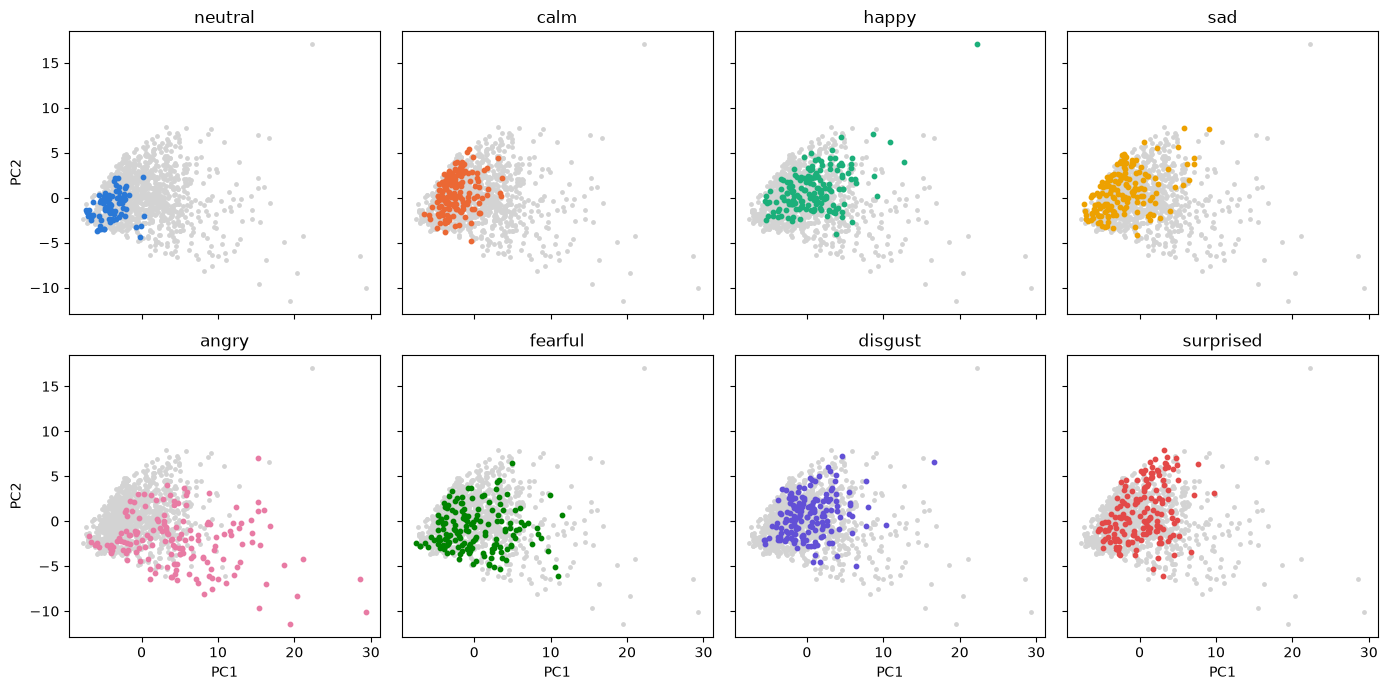

In [12]:
emotion_codes = dev_table.index.get_level_values("emotion")
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)

for i, (emotion_code, name) in enumerate(cfg.EMOTIONS.items()):
    ax = axes.flat[i]
    is_emotion = emotion_codes == emotion_code

    ax.scatter(scores[~is_emotion, 0], scores[~is_emotion, 1], s=6, color="lightgrey")
    ax.scatter(scores[is_emotion, 0], scores[is_emotion, 1], s=10, color=colors[i])
    ax.set_title(name)

for ax in axes[1]:
    ax.set_xlabel("PC1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

**Figure: the development videos on the first two components, by emotion.** Each panel highlights the videos of one emotion; the grey points are the videos of the other seven emotions. All panels share the same axes.

### Answer to Q5.1

Of the 55 components, 8 are needed to explain 75 % of the variance and 23 to explain 95 %. PC1 alone explains 36.5 % and PC2 13.3 %. A few components hold most of the variance because many features are strongly correlated with each other, as found in 3.4.

PC1 is spread over the six mouth measures, M1, M2, M3, own_M7, own_M8 and own_M10, each with about 12 to 13 % of the component and about 75 % together; no single measure dominates it. Its ten largest loadings have the same sign and are all `vel`, `range` or `energy` features, none of them a `mean`: PC1 grows with the amount of mouth movement in the video, not with the average shape of the mouth. PC2 is dominated by the eye and brow measures M4 (25.5 %) and M5 (20.8 %), and its largest loadings are again their movement features (`vel`, `range`, `std`, `energy`), with `M1_energy` as the only negative one in its top ten.

On the first two components the emotions overlap strongly. Neutral and calm stay in a compact region at low PC1, while angry is the only emotion that spreads far along PC1, towards negative PC2. The components are chosen without the emotion labels, to keep as much variance as possible, so two of them not separating the eight emotions does not really show that the 55 features cannot separate them.

## 5.2

### Pipelines
Three pipelines are evaluated under LOSO, all with `SVC(C=1)`, the value of `C_FIXED` chosen in 4.6:

- `StandardScaler → SVC`, with all 55 features;
- `StandardScaler → PCA(0.75) → SVC`, keeping the smallest number of components that explains 75 % of the variance;
- `StandardScaler → PCA(0.95) → SVC`, the same with 95 %.

Unlike 5.1, the scaler and the PCA are steps of the pipeline: in each of the 20 folds they are fitted on the 19 training actors only, and the held-out actor is only transformed.

In [13]:
X = dev_table.to_numpy()
y = dev_table.index.get_level_values("emotion").to_numpy()
groups = dev_table.index.get_level_values("actor").to_numpy()

pipe_all = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf", C=cfg.C_FIXED))])
pipe_pca75 = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=0.75)), ("svc", SVC(kernel="rbf", C=cfg.C_FIXED))])
pipe_pca95 = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=0.95)), ("svc", SVC(kernel="rbf", C=cfg.C_FIXED))])

per_fold_all, _, _ = evl.evaluation(X, y, LeaveOneGroupOut(), pipe_all, groups)
per_fold_pca75, _, _ = evl.evaluation(X, y, LeaveOneGroupOut(), pipe_pca75, groups)
per_fold_pca95, _, _ = evl.evaluation(X, y, LeaveOneGroupOut(), pipe_pca95, groups)

### Components kept in each fold

In [14]:
components_75 = sel.pca_components_per_fold(X, y, groups, 0.75)
components_95 = sel.pca_components_per_fold(X, y, groups, 0.95)

pd.DataFrame({"PCA 75 %": components_75["n_components"].value_counts().sort_index(),
              "PCA 95 %": components_95["n_components"].value_counts().sort_index()}).fillna(0).astype(int)

,PCA 75 %,PCA 95 %
n_components,,
8,20,0
22,0,13
23,0,7


**Table: number of components kept, counted over the 20 folds.** Each row is a number of components and each value is the number of folds in which the PCA, fitted on the 19 training actors, kept that number.

### Macro F1 of the three pipelines

In [15]:
pca_results = pd.DataFrame({"all 55 features": per_fold_all["macro_f1"].agg(["mean", "std"]),
                            "PCA 75 %": per_fold_pca75["macro_f1"].agg(["mean", "std"]),
                            "PCA 95 %": per_fold_pca95["macro_f1"].agg(["mean", "std"])}).T
pca_results.round(4)

,mean,std
all 55 features,0.5574,0.1460
PCA 75 %,0.4625,0.1348
PCA 95 %,0.5385,0.1510


**Table: LOSO macro F1 of the three pipelines.** Mean and standard deviation over the 20 held-out development actors, with `C = 1`.

### Paired comparison with all the features

In [ ]:
diff_75 = per_fold_pca75["macro_f1"].values - per_fold_all["macro_f1"].values
diff_95 = per_fold_pca95["macro_f1"].values - per_fold_all["macro_f1"].values

paired_rows = list()
for name, diff in [("PCA 75 % - all", diff_75), ("PCA 95 % - all", diff_95)]:
    paired_rows.append({"comparison": name,
                        "mean difference": diff.mean(),
                        "std of the differences": diff.std(ddof=1),
                        "actors improved": int((diff > 0).sum()),
                        "actors worse": int((diff < 0).sum())})

pd.DataFrame(paired_rows).set_index("comparison").round(4)

,mean difference,std of the differences,actors improved,actors worse
comparison,,,,
PCA 75 % - all,-0.0949,0.0887,3,17
PCA 95 % - all,-0.0190,0.0452,5,15


**Table: paired differences in macro F1, PCA minus all features.** For each held-out actor, the macro F1 of the PCA pipeline minus the macro F1 with all 55 features; mean and standard deviation of the 20 differences, and the number of actors with a higher or a lower score.

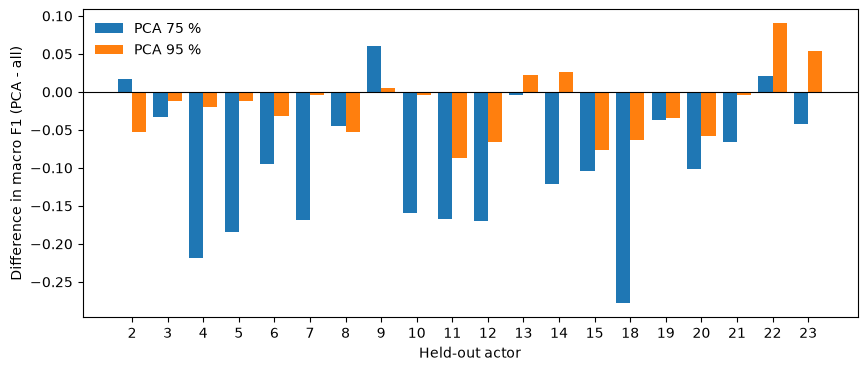

In [17]:
actors = per_fold_all["held_out_actor"].astype(str)
positions = np.arange(len(actors))
width = 0.4

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(positions - width / 2, diff_75, width, label="PCA 75 %")
ax.bar(positions + width / 2, diff_95, width, label="PCA 95 %")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(positions)
ax.set_xticklabels(actors)
ax.set_xlabel("Held-out actor")
ax.set_ylabel("Difference in macro F1 (PCA - all)")
ax.legend(frameon=False)
plt.show()

**Figure: difference in macro F1 per held-out actor, PCA minus all features.** One pair of bars per actor; bars below zero are actors whose score is lower with the PCA pipeline.

### Answer to Q5.2

Compressing the representation does not help the classifier. With all 55 features the LOSO macro F1 is 0.557 ± 0.146. Keeping 95 % of the variance (22 or 23 components, depending on the fold) gives 0.539 ± 0.151, and keeping 75 % (8 components in every fold) gives 0.463 ± 0.135.

Because the three pipelines are tested on the same actors, the fairer comparison is paired. With 95 % the loss is small, 0.019 on average with a standard deviation of 0.044, but 15 of the 20 actors get a lower score. With 75 % the loss is 0.095, with a standard deviation of 0.087, and 17 of the 20 actors get a lower score: here the loss is clearly larger than the variation between actors.

**Why.** PCA only rotates the standardised features: with all 55 components the distances between videos are the same as without PCA, and the RBF SVC depends only on those distances. What changes the model is dropping the last components. PCA orders the components by variance without looking at the emotion labels, so a direction with little variance is dropped even if it is the one that separates two emotions. As seen in 5.1, the largest components follow the amount of movement in the video, and the subtle differences, for example between neutral, calm and sad (4.4), may lie in the components with less variance. The 25 % of variance dropped at 75 % clearly holds information about the emotion; the 5 % dropped at 95 % holds a little. With 1200 videos and 55 features, the SVC with `C = 1` does not need fewer dimensions, so the compression removes information and gives nothing in exchange.